# K-Nearest-Neighbor (KNN) — 2D Classification Walkthrough

A self-contained notebook version of this repository's from-scratch **K-Nearest Neighbors (KNN)** implementation, built to teach the two core ideas behind KNN:

1. **Distance comparison** — measuring how "close" a new point is to every known point.
2. **Majority vote** — letting the closest points "vote" on what class the new point belongs to.

No `scikit-learn`, no black box — every step is plain NumPy so you can read and trace exactly what the algorithm does.

This notebook mirrors the same workflow as `main.py` in this project, but everything (data, algorithm, plotting) is defined directly in the cells below instead of being spread across `Process/*.py` and `config_dev.yaml` — so it can be read and run top to bottom on its own. The original config-driven scripts (`main.py`, `config_dev.yaml`, `Process/`) are untouched and still work the same way as before; this notebook is an additional, standalone walkthrough.

**Requirements:** `numpy`, `matplotlib`, and `pandas` (all listed in `requirements.txt`).

## 1. What is KNN?

K-Nearest Neighbors is a **classification algorithm** based on a simple idea:

> "You are the average of the people (points) closest to you."

Given a new, unlabeled point, KNN:

1. Measures the distance from that point to **every** point in the training data.
2. Picks the **k** points with the smallest distance (the "nearest neighbors").
3. Looks at the **class label** of those k neighbors and predicts the label that appears **most often** (majority vote).

KNN doesn't "train" a model in the usual sense — there's no equation being fitted. It just remembers all the training data and does the distance + vote calculation at prediction time. This is called a **lazy learner** / **instance-based learner**.

## 2. The Dataset

Every data point here has:

| Field | Meaning |
| --- | --- |
| `x` | Hours streamed per week (a feature) |
| `y` | Hours spent in ranked/competitive play per week (a feature) |
| `label` | The class the account belongs to (`0`, `1`, `2`) |

**The scenario:** a game-streaming platform wants to auto-tag creator accounts into three groups based on how they actually use the platform, so it can route them to the right creator program:

- **Streamer (0)** — streams a lot, but treats it as entertainment/variety content rather than ranked competition (high streamed hours, low competing hours).
- **Gamer (1)** — a casual player: streams little to occasionally, plays a moderate amount, not seriously ranked (low-to-moderate on both axes).
- **E-Sports (2)** — a competitive/professional player: spends most of their time in ranked play, streams only occasionally (e.g. practice VODs) (low-to-moderate streamed hours, high competing hours).

Unlike the original 4-point toy example, this is a hand-authored table of 19 accounts (6 Streamer, 6 Gamer, 7 E-Sports) with believable hour ranges, so the clusters and the decision boundary below actually look like real usage data instead of four arbitrary dots.

In [15]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle

# x = hours streamed per week, y = hours spent in ranked/competitive play per week
data_x = np.array([
    28, 22, 30, 18, 25, 33,      # Streamer
    6, 4, 9, 3, 8, 10,           # Gamer
    10, 5, 12, 7, 14, 4, 8         # E-Sports
], dtype=float)

data_y = np.array([
    4, 2.5, 6, 3, 1.5, 5,        # Streamer
    7, 5, 9, 4.5, 6, 10,         # Gamer
    22, 18, 26, 20, 28, 16.5, 32    # E-Sports
], dtype=float)

data_label = np.array([
    0, 0, 0, 0, 0, 0,
    1, 1, 1, 1, 1, 1,
    2, 2, 2, 2, 2, 2, 2,
])

label_names = {0: "Streamer", 1: "Gamer", 2: "E-Sports"}
colors = ["red", "blue", "green"]

xlabel = "Hours Streamed per Week"
ylabel = "Hours Competing (Ranked Play) per Week"

assert len(data_x) == len(data_y) == len(data_label) == 19
print(f"{len(data_x)} accounts loaded.")

19 accounts loaded.


### The `Data` container

A small container class for the dataset — same role as `Process/Data.py` in the original project — holding the coordinates, labels, and the colormap used for plotting. We'll also build a small pandas `DataFrame` right after it so the dataset is easy to inspect as a table.

In [9]:
class Data:
    def __init__(self, data_x, data_y, data_label, colors=colors):
        self.x = data_x
        self.y = data_y
        self.label = data_label            # <-- group 0/1/2, separate from x/y
        self.color_list = colors
        self.cmap = ListedColormap(colors)

    def __len__(self):
        return len(self.x)


data = Data(data_x, data_y, data_label)

# View the dataset as a table instead of one print() per point
df = pd.DataFrame({
    "x": data.x,
    "y": data.y,
    "label": data.label,
    "label_name": [label_names[lbl] for lbl in data.label],
})
df.index.name = "point"

print(f"{len(data)} points total")
df

19 points total


,x,y,label,label_name
point,,,,
0,28.0,4.0,0,Streamer
1,22.0,2.5,0,Streamer
2,30.0,6.0,0,Streamer
3,18.0,3.0,0,Streamer
4,25.0,1.5,0,Streamer
5,33.0,5.0,0,Streamer
6,6.0,7.0,1,Gamer
7,4.0,5.0,1,Gamer
8,9.0,9.0,1,Gamer


### Plotting the raw data

Before any prediction happens, let's just look at what the data looks like — a scatter plot colored by class. This is the notebook equivalent of `Plot.plot_data()`.

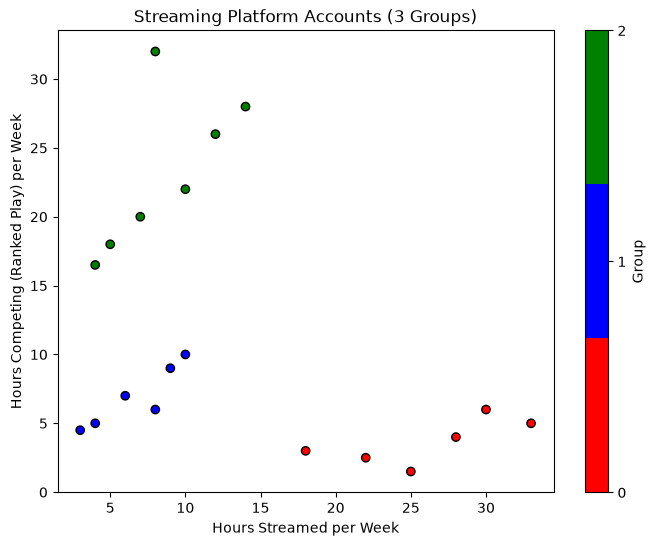

In [32]:
def plot_data(data, xlabel, ylabel):
    plt.figure(figsize=(8, 6))
    plt.scatter(data.x, data.y, c=data.label, cmap=data.cmap, edgecolor='k')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title('Streaming Platform Accounts (3 Groups)')
    plt.colorbar(ticks=sorted(set(data.label)), label='Group')
    plt.show()


plot_data(data, xlabel=xlabel, ylabel=ylabel)

## 3. Step-by-Step: How the Algorithm Works

We'll build up the algorithm in three steps, the same way `Process/Calculate.py` does it, and demo each step against a single test account: someone who streams **9 hours/week** and plays ranked **13 hours/week** — a borderline profile that could plausibly be a very active Gamer or a part-time E-Sports player.

### Step 1 — Calculate distance

For a new point `(point_x, point_y)`, compute the **Euclidean distance** to every training point:

```text
distance = √( (x_i - point_x)² + (y_i - point_y)² )
```

In [ ]:
def calculate_distance(data_x, data_y, point_x, point_y):
    """Euclidean distance from (point_x, point_y) to every training point."""
    return np.sqrt((data_x - point_x) ** 2 + (data_y - point_y) ** 2)


test_point_x, test_point_y = 9, 13
distances = calculate_distance(data_x, data_y, test_point_x, test_point_y)
df_distances = pd.DataFrame({
    "point": range(len(data_x)),
    "x": data_x,
    "y": data_y,
    "label": data_label,
    "distance": distances
})
#print(f"\nDistance from the test point to each of the {len(data_x)} accounts:")
#print(df_distances)
print(f"Distance from test point sorted by distance:")
print(df_distances.sort_values("distance"))

Distance from the test point to each of the 19 accounts:
    point     x     y  label   distance
0       0  28.0   4.0      0  21.023796
1       1  22.0   2.5      0  16.710775
2       2  30.0   6.0      0  22.135944
3       3  18.0   3.0      0  13.453624
4       4  25.0   1.5      0  19.704060
5       5  33.0   5.0      0  25.298221
6       6   6.0   7.0      1   6.708204
7       7   4.0   5.0      1   9.433981
8       8   9.0   9.0      1   4.000000
9       9   3.0   4.5      1  10.404326
10     10   8.0   6.0      1   7.071068
11     11  10.0  10.0      1   3.162278
12     12  10.0  22.0      2   9.055385
13     13   5.0  18.0      2   6.403124
14     14  12.0  26.0      2  13.341664
15     15   7.0  20.0      2   7.280110
16     16  14.0  28.0      2  15.811388
17     17   4.0  16.5      2   6.103278
18     18   8.0  32.0      2  19.026298
Distance from test point sorted by distance:
    point     x     y  label   distance
11     11  10.0  10.0      1   3.162278
8       8   9.0   

Thanks to NumPy vectorization, this line calculates the distance to **all** points at once (no `for` loop needed).

### Step 2 — Find the k nearest neighbors

In [43]:
def get_k_nearest_neighbors(data_x, data_y, data_label, point_x, point_y, k):
    """Labels of the k training points closest to (point_x, point_y)."""
    distances = calculate_distance(data_x, data_y, point_x, point_y)
    nearest_indices = np.argsort(distances)[:k]
    return data_label[nearest_indices]


k = 5
neighbor_labels = get_k_nearest_neighbors(data_x, data_y, data_label, test_point_x, test_point_y, k)
print(f"Labels of the {k} nearest neighbors:", [label_names[lbl] for lbl in neighbor_labels])

Labels of the 5 nearest neighbors: ['Gamer', 'Gamer', 'E-Sports', 'E-Sports', 'Gamer']


- `np.argsort(distances)` sorts the **indices** of the points by distance, smallest first.
- `[:k]` keeps only the first `k` — i.e. the indices of the `k` closest points.
- Looking those indices up in `data_label` gives the class of each of those neighbors.

### Step 3 — Majority vote

In [14]:
def predict_numeric_label(data_x, data_y, data_label, point_x, point_y, k):
    """Majority-vote label (as a number) among the k nearest neighbors."""
    neighbors_labels = get_k_nearest_neighbors(data_x, data_y, data_label, point_x, point_y, k)
    unique_labels, counts = np.unique(neighbors_labels, return_counts=True)
    majority_label = unique_labels[np.argmax(counts)]
    return majority_label


winner = predict_numeric_label(data_x, data_y, data_label, test_point_x, test_point_y, k)
print(f"Majority vote result: label {winner} -> {label_names[winner]}")

Majority vote result: label 1 -> Gamer


- `np.unique(..., return_counts=True)` counts how many times each label shows up among the k neighbors.
- `np.argmax(counts)` finds which label has the **highest count** — the "winner" of the vote.

> ℹ️ Tie-breaking: if two labels get the same number of votes, `np.unique` returns labels sorted from smallest to largest, so `np.argmax` picks the **first** (numerically smallest) label among the tied ones.

## 7. Things to Try (Exercises)

All of these are edits to the cells above — no other files need to change:

1. **Change `k`** in Section 3/5 (try `1`, `2`, `9`) and re-run the decision boundary cell. Small `k` → boundary follows individual points closely (can overfit / be noisy). Large `k` → boundary gets smoother but may ignore local structure.
2. **Add more accounts** to `data_x` / `data_y` / `data_label` in Section 2 and re-run everything below — watch the decision boundary regions reshape.
3. **Move the test point** (`test_point_x`, `test_point_y`) around and watch which neighbors light up and how the predicted class changes.
4. **Force a tie** on purpose (e.g. pick a test point equidistant from one account of each class) and confirm which label wins, to understand the tie-breaking rule from Step 3.
5. **Swap in a different real classification problem** you care about (e.g. billing tiers by usage minutes vs. monthly spend, or customer segments by two behavioral metrics) by replacing the dataset in Section 2 and the `xlabel`/`ylabel`/`label_names`.
6. **Compare against the config-driven CLI version** — `main.py` + `config_dev.yaml` in this repository run the same algorithm on a different (smaller) dataset, driven by a YAML file instead of notebook cells.

## 8. Limitations (by design, for learning)

This implementation is intentionally minimal so the algorithm stays readable — it does **not** include things a production KNN would need:

- No feature scaling/normalization — since `x` and `y` are on similar-ish scales here, this doesn't matter much for the demo, but with real, differently-scaled features you'd normally standardize features first (distance would otherwise be dominated by whichever feature has the larger numeric range).
- Only works with 2 features (`x`, `y`) — real KNN generalizes to any number of features/dimensions.
- Only Euclidean distance is implemented (other options include Manhattan or cosine distance).
- `k` is set manually rather than tuned automatically (e.g. via cross-validation).
- The dataset here, while more realistic than four arbitrary points, is still small and hand-authored rather than measured from a real streaming platform — it's built to make the clusters and the decision boundary easy to see and reason about, not to be a rigorous sample of real user behavior.

These are great follow-up topics once you're comfortable with the basic distance + majority-vote mechanics shown here.